# Linear algebra 5: Orthogonality, projections and least squares

*Learning path: linear algebra, part 5 of 9.* [Index](README.md) · Previous: [Determinants](04-determinants.ipynb) · Next: [Eigenvalues](06-eigenvalues.ipynb)

You measure the same quantity five times and get five slightly different numbers. You fit a line through a hundred
noisy data points. A GPS receiver gets signals from eight satellites but has only four unknowns (position and clock).
In each case there are **more equations than unknowns, and no exact solution**. The best you can do is come as close as
possible, and "as close as possible" turns out to mean a right angle: the error must be **perpendicular** to everything
you could have reached. This lesson builds that idea from projections to least squares, Gram–Schmidt and $A = QR$.

**Who this is for.** You know the dot product ([lesson 1](01-vectors-and-matrices.ipynb)), column spaces and null
spaces ([lesson 3](03-vector-spaces.ipynb)).

**What you will be able to do afterwards:**

1. project a vector onto a line and onto a subspace, with a projection matrix;
2. solve least squares problems with the normal equations $A^TA\hat x = A^Tb$, and fit lines to data;
3. turn any basis into an orthonormal one with Gram–Schmidt;
4. factor $A = QR$ and explain why orthonormal columns make everything easier.

Plan about an hour and a half.

## 1. Projecting onto a line

The **projection** of $b$ onto the line through $a$ is the point $p$ on the line closest to $b$. Closest means the
error $e = b - p$ is perpendicular to $a$. Write $p = \hat x\,a$; then $a\cdot(b - \hat x a) = 0$ gives

$$\hat x = \frac{a\cdot b}{a\cdot a}, \qquad p = \frac{a\cdot b}{a\cdot a}\,a.$$

For $a = [2\ 1]$ and $b = [1\ 3]$: $a\cdot b = 5$ and $a\cdot a = 5$, so $p = a$ and $e = [-1\ 2]$.

In [1]:
a = [2; 1];
b = [1; 3];
p = simplify(dot(a, b)/dot(a, a)*a)
e = simplify(b - p)
dot(a, e)

[2;
 1]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

[-1;
  2]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

0

> `dot`: Dot product of two vectors, and cross product of two vectors of length 3.

The plot draws $a$ (extended along its line), $b$, its projection $p$, and the error $e$ from $p$ to $b$, which meets the
line at a right angle. Axes: the coordinates $x$ and $y$ (the two axes have different scales, so the right angle looks
slightly squashed).

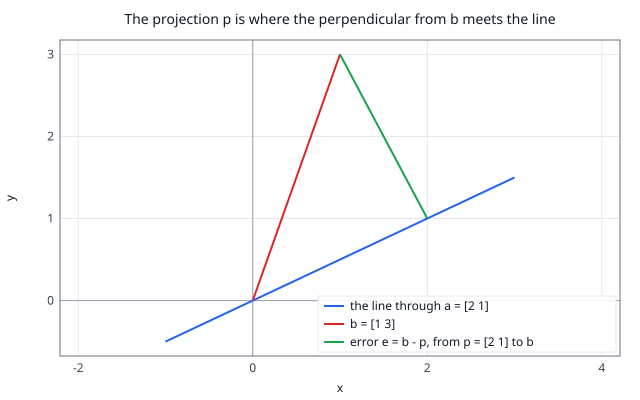

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [2]:
q = show(parametric(2*s, s, s, -0.5, 1.5), parametric(s, 3*s, s, 0, 1), parametric(2 - s, 1 + 2*s, s, 0, 1));
q = legend(q, "the line through a = [2 1]", "b = [1 3]", "error e = b - p, from p = [2 1] to b");
labels(title(q, "The projection p is where the perpendicular from b meets the line"), "x", "y")

The projection is a linear map, so it has a matrix: $p = Pb$ with

$$P = \frac{a\,a^T}{a^Ta}.$$

Projecting twice changes nothing, so $P^2 = P$; and $P$ is symmetric.

In [3]:
P = simplify(a*transpose(a)/dot(a, a))
simplify(P*b)
simplify(P*P - P)

[4/5, 2/5;
 2/5, 1/5]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

[2;
 1]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

[0, 0;
 0, 0]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

**Try this.** Project $b = [1\ 1\ 1]$ onto the line through $a = [1\ 2\ 2]$ by hand. Check that $e = b - p$ is
perpendicular to $a$.

## 2. Projecting onto a subspace: the normal equations

Now project $b$ onto the column space of a matrix $A$ (a plane, say). The projection is $p = A\hat x$ for some
coefficients $\hat x$, and the error $b - A\hat x$ must be perpendicular to *every* column of $A$, that is,
$A^T(b - A\hat x) = 0$. These are the **normal equations**:

$$A^TA\,\hat x = A^Tb, \qquad p = A\hat x, \qquad P = A(A^TA)^{-1}A^T.$$

(They need independent columns, so that $A^TA$ is invertible.) The error lies in the left null space $N(A^T)$, which
is exactly the space perpendicular to $C(A)$, as in lesson 3, section 4.

In [4]:
A = [1 0; 1 1; 1 2];
b = [6; 0; 0];
simplify(transpose(A)*A)
simplify(transpose(A)*b)
xhat = (transpose(A)*A)\(transpose(A)*b)
e = simplify(b - A*xhat)
simplify(transpose(A)*e)

[3, 3;
 3, 5]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

[6;
 0]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

[ 5;
 -3]
[ 1;
 -2;
  1]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

[0;
 0]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

The error $e = [1\ {-2}\ 1]$ is perpendicular to both columns. With more equations than unknowns, `A\b` solves the
normal equations for you:

In [5]:
A\b

[ 5;
 -3]

**Try this.** Compute the projection matrix $P = A(A^TA)^{-1}A^T$ for this $A$ and check $P^2 = P$. What is $Pb$?

## 3. Least squares: the best line through data

The three equations above came from a question: which line $y = C + Dt$ passes closest to the points
$(0, 6)$, $(1, 0)$, $(2, 0)$? Each point gives an equation $C + Dt_i = y_i$:

$$C + 0D = 6, \qquad C + 1D = 0, \qquad C + 2D = 0,$$

the system $A[C\ D]^T = b$ of section 2. No line passes through all three, and the least squares solution
$C = 5$, $D = -3$ minimizes the **sum of squared errors** $|b - A\hat x|^2 = 1 + 4 + 1 = 6$. Why the same answer? The
point of the column space closest to $b$ is the projection: the shortest error vector is the perpendicular one.

A bigger example: five measurements of a quantity that should grow linearly. The columns of the matrix are a column
of ones (for $C$) and the times (for $D$):

In [6]:
y = [2.1; 3.9; 6.2; 7.8; 10.1];
X = [1 1; 1 2; 1 3; 1 4; 1 5];
X\y

[0.05;
 1.99]

The best line is $y = 0.05 + 1.99\,t$, the same as by minimizing the sum of squares with partial derivatives in
[multivariable lesson 3](../multivariable/03-optimization.ipynb): setting the gradient to zero *is* the normal
equations. The plot has the time across and the measurement up:

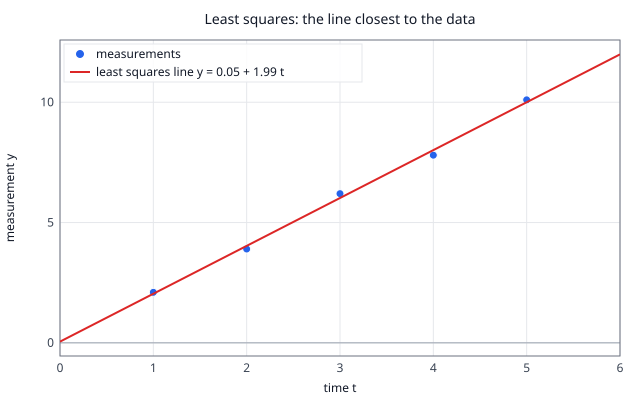

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [7]:
D = [1 2.1; 2 3.9; 3 6.2; 4 7.8; 5 10.1];
q = show(scatter(D, [t y]), plot(0.05 + 1.99*t, t, 0, 6));
q = legend(q, "measurements", "least squares line y = 0.05 + 1.99 t");
labels(title(q, "Least squares: the line closest to the data"), "time t", "measurement y")

Fitting a parabola $C + Dt + Et^2$ is the same: add a column of $t^2$. Least squares is linear in the unknown
coefficients, even when the curve is not a line.

**Try this.** Fit the best horizontal line $y = C$ to the five measurements (the matrix is a single column of ones).
What familiar number is $C$?

## 4. Orthonormal bases and Gram–Schmidt

Vectors $q_1, \ldots, q_n$ are **orthonormal** if they are perpendicular unit vectors: $q_i\cdot q_j = 0$ for
$i \ne j$ and $q_i\cdot q_i = 1$. Put them in the columns of $Q$; then all of that says

$$Q^TQ = I.$$

With an orthonormal basis everything is easy: the coordinates of $b$ are just the dot products $q_i\cdot b$ (no system
to solve), projections are $QQ^Tb$, and the normal equations become $\hat x = Q^Tb$. A square $Q$ with
$Q^TQ = I$ is an **orthogonal matrix**: $Q^{-1} = Q^T$, and it keeps lengths and angles, like the rotations of lesson 1.

**Gram–Schmidt** makes any independent vectors orthonormal. Take the first and divide by its length. Take the second,
subtract its projection onto the first (section 1), and normalize what is left. Take the third, subtract its
projections onto the first two, normalize, and so on.

In [8]:
Q = gramschmidt([1 1; 1 0; 0 1])
simplify(transpose(Q)*Q)

[sqrt(2)/2,  sqrt(6)/6;
 sqrt(2)/2, -sqrt(6)/6;
         0,  sqrt(6)/3]

> Gram–Schmidt takes the columns one at a time, subtracts their projections on the directions found so far, and divides by the length: q₁ = a₁/|a₁|, then q₂ is a₂ − (q₁·a₂)q₁ normalized, and so on. 2 of the 2 columns were independent, so the columns of the result are an orthonormal basis of the column space (dimension 2).

[1, 0;
 0, 1]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

By hand: $a_1 = [1\ 1\ 0]$ has length $\sqrt2$, so $q_1 = [1\ 1\ 0]/\sqrt2$. Then
$a_2 - (q_1\cdot a_2)q_1 = [1\ 0\ 1] - \tfrac12[1\ 1\ 0] = [\tfrac12\ {-\tfrac12}\ 1]$, of length $\sqrt{3/2}$, which
normalizes to $[1\ {-1}\ 2]/\sqrt6$. The square roots are why Galileo writes $\sqrt6/6 = 1/\sqrt6$.

**Try this.** Check by hand that the two columns of `Q` are perpendicular and have length 1.

## 5. $A = QR$

Gram–Schmidt is another factorization. Each $a_j$ is a combination of $q_1, \ldots, q_j$ (the directions found so
far), with coefficients $q_i\cdot a_j$. Collect them in an upper triangular $R$:

$$A = QR, \qquad R_{ij} = q_i\cdot a_j.$$

In [9]:
[Q, R] = qr(A)
simplify(Q*R)

Q = [sqrt(3)/3, -sqrt(2)/2;
 sqrt(3)/3,          0;
 sqrt(3)/3,  sqrt(2)/2]
R = [sqrt(3), sqrt(3);
       0, sqrt(2)]

> A = Q*R: Q has orthonormal columns (Gram–Schmidt on the columns of A, QᵀQ = I) and R is upper triangular with R[i, j] = q_i · a_j. Least squares A x ≈ b becomes R x = Qᵀ b.

[1, 0;
 1, 1;
 1, 2]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

Least squares with $A = QR$: the normal equations $A^TA\hat x = A^Tb$ become $R^TQ^TQR\hat x = R^TQ^Tb$, that is,
$R\hat x = Q^Tb$, one triangular system:

In [10]:
R\(transpose(Q)*b)

[ 5;
 -3]

Again $C = 5$, $D = -3$. This is how good software solves least squares: forming $A^TA$ squares the condition number
(small errors in the data get amplified much more), while $QR$ does not. Numerical libraries compute $Q$ with
Householder reflections rather than Gram–Schmidt, for the same reason.

**Try this.** For $A = [3\ 1;\ 4\ 2]$ compute $q_1$ and $R_{11}$ by hand (hint: $|[3\ 4]| = 5$), then check with `qr`.

## Exercises

1. **Projection matrices.** Find the matrix $P$ that projects onto the line through $[1\ 1\ 1]$. What are its rank, its
   column space and its null space?
2. **Perpendicular complement.** Show that the projection onto the plane $x + y + z = 0$ is $I - P$ with the $P$ of
   exercise 1. Why?
3. **A parabola.** Fit $y = C + Dt + Et^2$ to the points $(-1, 2)$, $(0, 0)$, $(1, 1)$, $(2, 5)$.
4. **Gram–Schmidt by hand.** Make $[1\ 0\ 1]$, $[1\ 1\ 0]$, $[0\ 1\ 1]$ orthonormal, then check with `gramschmidt`.
5. **Lengths.** Show that $|Qx| = |x|$ when $Q^TQ = I$. (Hint: $|Qx|^2 = (Qx)^T(Qx)$.)

## Hints and answers

* **Section 1, Try this.** $a\cdot b = 5$, $a\cdot a = 9$: $p = \tfrac59[1\ 2\ 2]$, $e = [4/9\ \ {-1/9}\ \ {-1/9}]$,
  and $a\cdot e = (4 - 2 - 2)/9 = 0$.
* **Section 2, Try this.** `PA = A*inv(transpose(A)*A)*transpose(A)` gives $[5/6\ 1/3\ {-1/6};\ 1/3\ 1/3\ 1/3;\
  {-1/6}\ 1/3\ 5/6]$, and $Pb = [5\ 2\ {-1}] = A\hat x$.
* **Section 3, Try this.** $C$ is the average, $30.1/5 = 6.02$: `ones(5, 1)\y`.
* **Section 4, Try this.** $(1 - 1 + 0)/\sqrt{12} = 0$; $1/2 + 1/2 = 1$ and $1/6 + 1/6 + 4/6 = 1$.
* **Section 5, Try this.** $q_1 = [3/5\ \ 4/5]$, $R_{11} = 5$, $R_{12} = q_1\cdot[1\ 2] = 11/5$.
* **Exercise 1.** $P = \tfrac13$ times the all-ones matrix; rank 1, column space the line through $[1\ 1\ 1]$, null space
  the plane $x + y + z = 0$.
* **Exercise 2.** $b = Pb + (I - P)b$ splits $b$ into a part along $[1\ 1\ 1]$ and a part perpendicular to it, which
  is in the plane.
* **Exercise 3.** The columns are $1, t, t^2$: `[1 -1 1; 1 0 0; 1 1 1; 1 2 4]\[2; 0; 1; 5]` gives
  $C = 0$, $D = -1/2$, $E = 3/2$, so $y = -t/2 + 3t^2/2$.
* **Exercise 4.** $[1\ 0\ 1]/\sqrt2$, $[1\ 2\ {-1}]/\sqrt6$, $[-1\ 1\ 1]/\sqrt3$.
* **Exercise 5.** $|Qx|^2 = x^TQ^TQx = x^Tx = |x|^2$.

## Sources

1. G. Strang, *Introduction to Linear Algebra*, 6th ed., Wellesley-Cambridge Press (2023), chapter 4.
2. D. C. Lay, S. R. Lay and J. J. McDonald, *Linear Algebra and Its Applications*, 6th ed., Pearson (2021), chapter 6.
3. A.-M. Legendre, *Nouvelles méthodes pour la détermination des orbites des comètes* (1805): the first publication of
   least squares.
4. L. N. Trefethen and D. Bau, *Numerical Linear Algebra*, SIAM (1997), lectures 7 to 11 (QR and least squares).